# H10. 센서 값은 정규분포이고 그룹별 분산이 같은가 (검정 방법 선택 근거)

| 항목 | 내용 |
|---|---|
| 질문 | ANOVA·t-검정을 써도 될까, 비모수 검정을 써야 할까? |
| 귀무가설 H0 | 각 상태 그룹의 값은 정규분포이고, 그룹끼리 분산이 같다 |
| 대립가설 H1 | 정규분포가 아니거나 분산이 다르다 |
| 검정 | D'Agostino K²(그룹별), Shapiro-Wilk(참고), Levene(중앙값 기준) |
| 출처 (EDA) | F08 히스토그램, F24 Q-Q 플롯 |
| 데이터 | 가설 1~4의 주요 특징 5개 × 해당 부품 |
| 왜 중요한가 | 가설 1~3에서 Kruskal-Wallis를 쓴 근거 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화: 그룹별 히스토그램

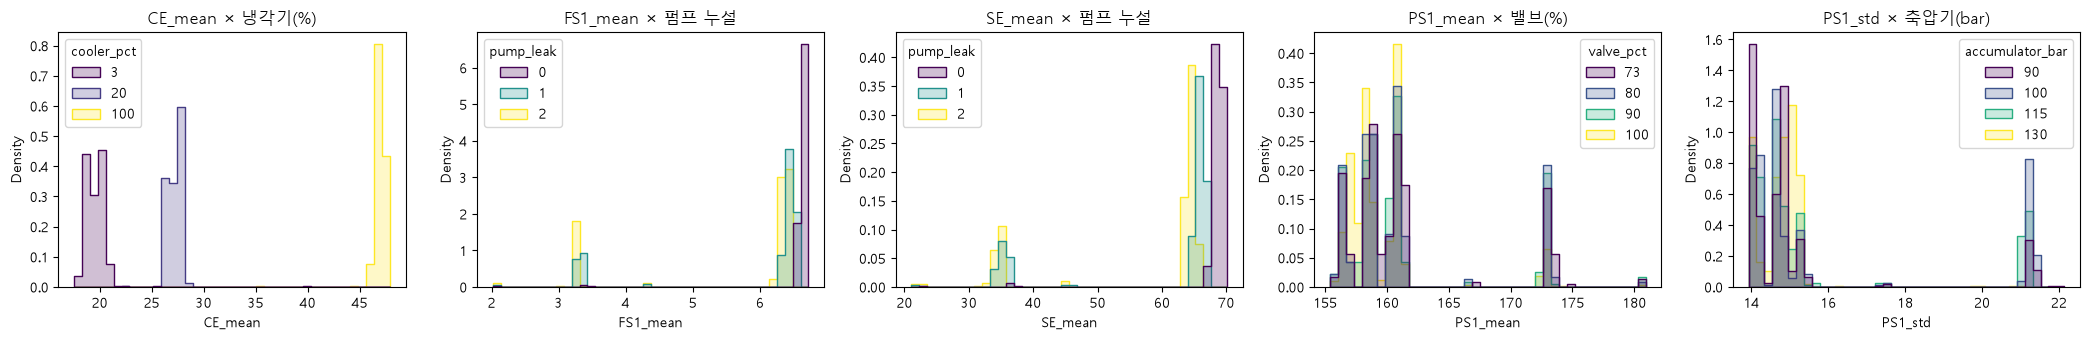

In [2]:
PAIRS = [("CE_mean", "cooler_pct"), ("FS1_mean", "pump_leak"), ("SE_mean", "pump_leak"), ("PS1_mean", "valve_pct"), ("PS1_std", "accumulator_bar")]
fig, axes = plt.subplots(1, 5, figsize=(21, 3.5))
for ax, (f, c) in zip(axes, PAIRS):
    sns.histplot(data=cyc, x=f, hue=c, ax=ax, bins=40, element="step", stat="density", common_norm=False, palette="viridis"); ax.set_title(f"{f} × {COMP[c]}")
plt.tight_layout(); plt.show()

**EDA로 본 것:** 그룹마다 봉우리가 여러 개이거나 한쪽으로 치우쳐 있고, 퍼진 정도도 다릅니다.

## 2. 기술통계: 왜도·첨도

In [3]:
rows = [dict(특징=f, 부품=COMP[c], 그룹=g, n=len(v), 왜도=stats.skew(v), 첨도=stats.kurtosis(v), 표준편차=v.std()) for f, c in PAIRS for g, v in cyc.groupby(c)[f]]
display(pd.DataFrame(rows).round(2))

,특징,부품,그룹,n,왜도,첨도,표준편차
0,CE_mean,냉각기(%),3,732,9.67,178.50,1.05
1,CE_mean,냉각기(%),20,732,-0.93,2.83,0.60
2,CE_mean,냉각기(%),100,741,-11.01,218.80,0.56
3,FS1_mean,펌프 누설,0,1221,-8.93,80.92,0.38
4,FS1_mean,펌프 누설,1,492,-1.43,0.14,1.30
5,FS1_mean,펌프 누설,2,492,-1.25,-0.32,1.35
6,SE_mean,펌프 누설,0,1221,-8.67,78.09,3.82
7,SE_mean,펌프 누설,1,492,-1.44,0.17,12.60
8,SE_mean,펌프 누설,2,492,-1.26,-0.28,13.07
9,PS1_mean,밸브(%),73,360,1.63,1.44,5.51


## 3·5. 가설검정 (p-값)

- **D'Agostino K²:** 왜도와 첨도로 정규성을 봅니다. 큰 표본에 적합합니다.
- **Shapiro-Wilk:** 참고용입니다. n > 5,000에서는 쓰지 않는 것이 보통이고, 여기서도 큰 표본이라 거의 항상 기각됩니다.
- **Levene:** 중앙값 기준(Brown-Forsythe)이라 정규분포가 아니어도 안정적입니다.

In [4]:
rows = []
for f, c in PAIRS:
    tab, lev = assumption_table(cyc[f], cyc[c])
    sw = [stats.shapiro(v)[1] for _, v in cyc.groupby(c)[f]]
    rows.append(dict(특징=f, 부품=COMP[c], 그룹수=len(tab), 정규성기각_그룹=int((tab.정규성_p < ALPHA).sum()), K2_p최대=tab.정규성_p.max(),
                     Shapiro_p최대=max(sw), Levene_W=lev["W"], Levene_p=lev["p"]))
res = pd.DataFrame(rows); res["Levene_p_holm"] = holm(res["Levene_p"])
display(res.style.format({"K2_p최대": "{:.2e}", "Shapiro_p최대": "{:.2e}", "Levene_W": "{:.1f}", "Levene_p": "{:.2e}", "Levene_p_holm": "{:.2e}"}))

,특징,부품,그룹수,정규성기각_그룹,K2_p최대,Shapiro_p최대,Levene_W,Levene_p,Levene_p_holm
0,CE_mean,냉각기(%),3,3,1.45e-29,7.48e-22,56.4,1.28e-24,2.55e-24
1,FS1_mean,펌프 누설,3,3,1.72e-19,1.10e-32,144.9,7.54e-60,3.77e-59
2,SE_mean,펌프 누설,3,3,1.87e-19,3.89e-32,141.9,1.05e-58,4.19e-58
3,PS1_mean,밸브(%),4,4,7.99e-23,3.02e-24,18.3,1.02e-11,1.02e-11
4,PS1_std,축압기(bar),4,4,2.62e-16,1.58e-28,51.0,7.59e-32,2.28e-31


## 4. 정상성과의 관계

분포가 여러 봉우리인 이유 중 하나는 **시간에 따른 이동(비정상)**입니다. 같은 상태 안에서도 시간대마다 값이 달라 분포가 섞입니다.

,특징,계열,ADF_p,KPSS_p,판정
0,CE_mean,원값,0.8326,0.010,비정상
1,CE_mean,1차 차분,0.0000,0.100,정상
2,FS1_mean,원값,0.0021,0.010,추세·구조변화(둘 다 기각)
3,FS1_mean,1차 차분,0.0000,0.100,정상
4,SE_mean,원값,0.0008,0.010,추세·구조변화(둘 다 기각)
5,SE_mean,1차 차분,0.0000,0.100,정상
6,PS1_mean,원값,0.0002,0.100,정상
7,PS1_mean,1차 차분,0.0000,0.100,정상
8,PS1_std,원값,0.0206,0.010,추세·구조변화(둘 다 기각)
9,PS1_std,1차 차분,0.0000,0.100,정상


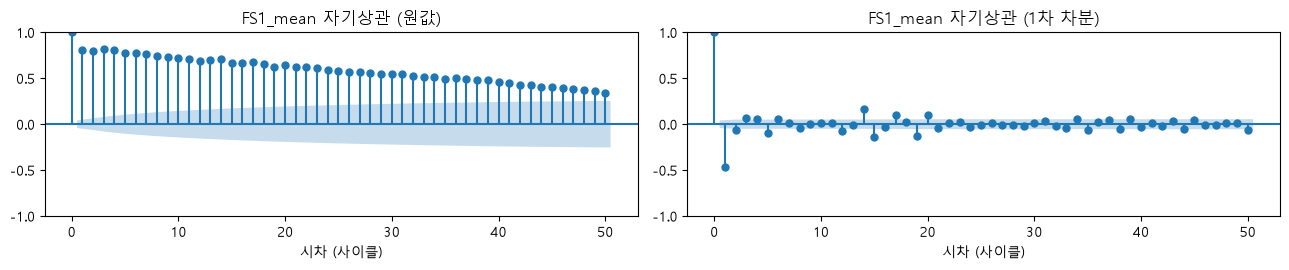

In [5]:
st = stationarity(cyc, ['CE_mean', 'FS1_mean', 'SE_mean', 'PS1_mean', 'PS1_std'])
display(st.style.format({"ADF_p": "{:.4f}", "KPSS_p": "{:.3f}"}))
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
acf_plot(cyc['FS1_mean'], "FS1_mean 자기상관 (원값)", ax=axes[0])
acf_plot(cyc['FS1_mean'].diff(), "FS1_mean 자기상관 (1차 차분)", ax=axes[1])
plt.tight_layout(); plt.show()

## 6. 효과 크기: Q-Q 플롯으로 벗어난 정도 보기

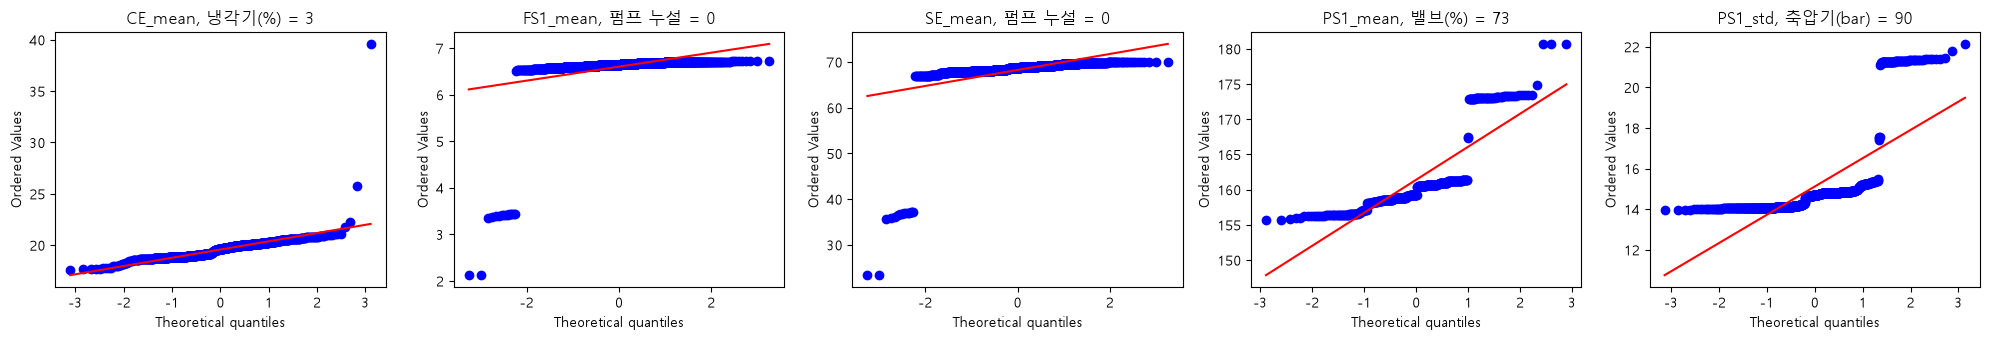

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, (f, c) in zip(axes, PAIRS):
    g0 = sorted(cyc[c].unique())[0]; stats.probplot(cyc.loc[cyc[c] == g0, f].dropna(), dist="norm", plot=ax); ax.set_title(f"{f}, {COMP[c]} = {g0}")
plt.tight_layout(); plt.show()

## 7. 재확인: 블록 평균도 정규분포가 아닌가

평균을 내면 중심극한정리 때문에 정규분포에 가까워질 수 있어서 확인합니다.

In [7]:
for f, c in PAIRS:
    b = block_means(cyc, f, c); tab, lev = assumption_table(b[f], b[c])
    print(f"{f}: 블록 평균 기준 정규성 기각 그룹 {(tab.정규성_p < ALPHA).sum()}/{len(tab)}, Levene p = {lev['p']:.2e}")

CE_mean: 블록 평균 기준 정규성 기각 그룹 0/3, Levene p = 1.35e-01
FS1_mean: 블록 평균 기준 정규성 기각 그룹 3/3, Levene p = 1.10e-02
SE_mean: 블록 평균 기준 정규성 기각 그룹 3/3, Levene p = 1.11e-02
PS1_mean: 블록 평균 기준 정규성 기각 그룹 4/4, Levene p = 8.87e-01
PS1_std: 블록 평균 기준 정규성 기각 그룹 2/4, Levene p = 2.36e-01


## 8. 최종 판정

In [8]:
final = pd.DataFrame([dict(가설="H10", 검정="D'Agostino K² + Levene", 정규성기각=f"{res.정규성기각_그룹.sum()}/{res.그룹수.sum()} 그룹",
    등분산기각=f"{(res.Levene_p_holm < ALPHA).sum()}/{len(res)} 특징", p_최대=res.Levene_p_holm.max(),
    판정="H0 기각 (비모수 검정 사용)" if (res.Levene_p_holm < ALPHA).all() and res.정규성기각_그룹.sum() == res.그룹수.sum() else "일부 성립")])
display(final)
save_result("H10", title="정규성·등분산", test="D'Agostino K², Levene", stat=f"Levene W = {res.Levene_W.min():.0f}~{res.Levene_W.max():.0f}",
            p=float(res.Levene_p_holm.max()), effect=f"정규성 기각 {res.정규성기각_그룹.sum()}/{res.그룹수.sum()} 그룹", verdict=final.판정[0])

,가설,검정,정규성기각,등분산기각,p_최대,판정
0,H10,D'Agostino K² + Levene,17/17 그룹,5/5 특징,1.018731e-11,H0 기각 (비모수 검정 사용)


저장: results/H10.json


## 9. 해석과 결정

- 모든 그룹에서 정규성이 기각되고, 분산도 그룹마다 다릅니다.
- **결정:** 정규분포를 가정하는 ANOVA·t-검정 대신 **Kruskal-Wallis 같은 비모수 검정**을 씁니다. 가설 1~3의 검정 방법 선택 근거입니다.
- 참고: Kruskal-Wallis도 그룹 분포 모양이 비슷해야 "중앙값 차이"로 해석할 수 있습니다. 모양이 다르므로 결과는 **"분포가 다르다"**로 해석합니다.